In [2]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
from scipy import stats
from multicam.multicam import MultiCAM
from multicam.multicam import MultiCamSampling
import pickle

TNG_H = 0.6774
COLOR_CUT = 0.85

In [3]:
## Load data ###
dmo_full = pd.read_csv('data/cache_files/dmo_tree_data.csv', usecols=['SubhaloMass', 'logSubhaloMass', 
                                                                      'vpeak', 'vpeak_pre', 
                                                                      'mpeak_pre', 'mpeak', 
                                                                      'x', 'y', 'z', 'a12'])
print("\nDMO Table:")
print(len(dmo_full))

hydro_full = pd.read_csv(
    'data/cache_files/hydro_color_tree_subhaloflag_check_data.csv',
    usecols=[
        'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
        'logStellarMass', 'logSubhaloMass', 'g-i',
        'vpeak', 'a12', 'mpeak',
        *[f'mpeak_mah{ii}' for ii in range(100)]
    ]
)

print("\nHydro Table")
print(len(hydro_full))

print("\nCache files read in!")

# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= (1.4 * 10**8 * TNG_H)] # units of Msun
print("\nNew Hydro Table Length:")
print(len(hydro_full))

# Add z12 column to hydro_full
hydro_full['z12'] = (1 / hydro_full['a12']) - 1
print(hydro_full)

# Pick top whatever of DMO and then do SHAM
dmo_full = dmo_full.sort_values('vpeak', ascending=False).head(len(hydro_full))
print("\nNew DMO Table Length:")
print(len(dmo_full))

# Add z12 column to dmo_full

dmo_full['z12'] = (1 / dmo_full['a12']) - 1
print(hydro_full)
print(dmo_full)


DMO Table:
533674

Hydro Table
101364

Cache files read in!

New Hydro Table Length:
21771
         SubhaloMass   StellarMass          x          y          z  \
0       2.747794e+14  1.638342e+12   0.849091  26.326996  18.306934   
1       3.666623e+13  2.573102e+11   0.106473  24.633322  16.900553   
2       7.734555e+12  2.885268e+11   0.853112  26.725748  17.510680   
3       3.253667e+12  6.276475e+10   0.768784  26.518290  15.530523   
4       2.980181e+12  8.770330e+10   1.426592  26.341442  19.041204   
...              ...           ...        ...        ...        ...   
100110  5.506356e+09  2.442531e+08  65.244316  14.453114  32.561405   
100239  4.163340e+09  3.376348e+08  21.512703  73.824860  19.064798   
100245  5.602026e+09  2.337010e+08  23.715452  36.721306  42.095657   
100354  3.967491e+09  3.418285e+08  40.340150  37.721676  57.260925   
100384  4.172430e+09  3.815481e+08  66.217720  60.654682  54.770990   

        logSubhaloMass  logStellarMass       vpeak     

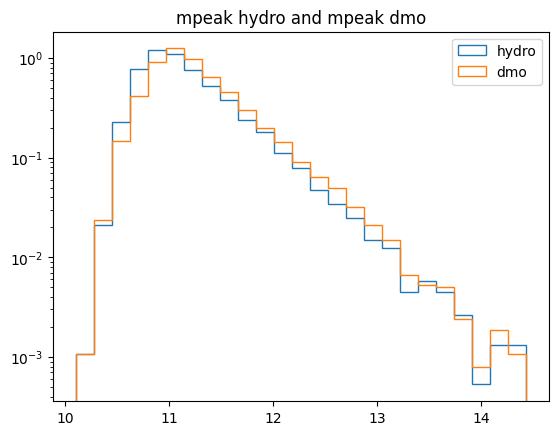

In [4]:
__, bins, __ = plt.hist(np.log10(hydro_full['mpeak']), bins = 25, density = True, histtype = 'step', label = "hydro");
plt.hist(np.log10(dmo_full['mpeak']), bins = bins, density = True, histtype = 'step', label = "dmo");
plt.yscale("log")
plt.legend()
plt.title("mpeak hydro and mpeak dmo");